# Inference and evaluation

This notebook accepts DINOv2 architecture checkpoints from vision pretraining
(`train_vision_dinov2.py`) and staged fine-tuning (`train_tot_dinov2.py`).

Vision checkpoints support vision plots and metrics. They do not contain a trained
pose head, so pose evaluation is skipped. Joint checkpoints support both vision and
pose evaluation. Pose inference uses predicted occupancy bins and predicted
descriptor matches; GT camera poses are used only to score the predictions. The
optional vision subset is selected using GT cylinder matches and a valid camera
baseline.


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset

from dataset import SceneTwoPairsDataset
from model_dinov2 import PairImageCylinderModel, gt_bin_matches
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text

# Use best_vision.pt from train_vision_dinov2.py or best_pose.pt from train_tot_dinov2.py.
CHECKPOINT = Path("arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt")
TEST_DATASET = Path("testdataset")

VISION_ON_GT_POSE_SUBSET = False  # Limit vision metrics to pairs with GT pose matches.
MODEL_VERSION = "DINOv2 best_pose"  # Descriptive label for plots.
INFERENCE_BATCH_SIZE = 4
VISION_SAMPLE_IDX = 0
IMG_SIZE = 224
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
OCC_THRESHOLD = 0.3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT)
print("Test dataset:", TEST_DATASET)


Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Checkpoint: arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt
Test dataset: testdataset


In [2]:
import torch.nn.functional as F

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
training_args = checkpoint.get("args", {})
state = checkpoint["model_state_dict"]
training_stage = checkpoint.get("training_stage", "")
IS_VISION_CHECKPOINT = training_stage.startswith("vision_")
HAS_TRAINED_POSE = not IS_VISION_CHECKPOINT and "pose_head.token_mlp.0.weight" in state

model_kwargs = dict(
    img_size=training_args.get("img_size", 224),
    patch_size=tuple(training_args.get("patch_size", (16, 4))),
    in_chans=3,
    embed_dim=training_args.get("embed_dim", 192),
    depth=training_args.get("depth", 4),
    num_heads=training_args.get("num_heads", 4),
    num_bins=training_args.get("num_bins", 128),
    dropout=training_args.get("dropout", 0.1),
)

if HAS_TRAINED_POSE:
    scale = state["pose_head.input_scale"]
    model_kwargs.update(
        pose_embed_dim=state["pose_head.token_mlp.0.weight"].shape[0],
        pose_depth=len({key.split(".")[3] for key in state
                        if key.startswith("pose_head.blocks.layers.")}),
        fov_degrees=float(scale[0]) * 360 / np.pi,
        radius_scale=float(scale[1]),
        distance_scale=float(scale[2]),
    )

model = PairImageCylinderModel(**model_kwargs)
if IS_VISION_CHECKPOINT:
    # Vision pretraining saves a full model state, but its pose head is untrained.
    vision_state = {key: value for key, value in state.items()
                    if key.startswith(("backbone.", "vision_head.", "corr_decoder."))}
    expected = {key for key in model.state_dict()
                if key.startswith(("backbone.", "vision_head.", "corr_decoder."))}
    if set(vision_state) != expected:
        raise ValueError("Vision checkpoint does not match the model's vision modules.")
    model.load_state_dict(vision_state, strict=False)
else:
    model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
history = checkpoint.get("history")
GT_OCC_THRESHOLD = training_args.get("occ_thresh", 0.5)
print(f"Loaded checkpoint: {CHECKPOINT}")
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Training stage:", training_stage or "unspecified")
print("Trained pose head:", HAS_TRAINED_POSE)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
if HAS_TRAINED_POSE:
    print("Pose matching: predicted occupancy bins and descriptor matches (no GT cylinders).")
else:
    print("Vision-only checkpoint: pose evaluation will be skipped.")


Using cache found in /home/johanna/.cache/torch/hub/facebookresearch_dinov2_main
/home/johanna/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/johanna/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/johanna/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Loaded checkpoint: arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt
Checkpoint epoch: 190
Training stage: pose_refine
Trained pose head: True
Model parameters: 26,456,649
Pose matching: predicted occupancy bins and descriptor matches (no GT cylinders).


In [3]:
infer_dataset = SceneTwoPairsDataset(
    root_dir=str(TEST_DATASET),
    image_size=training_args.get("img_size", IMG_SIZE),
    return_two_pairs=False,
)
infer_loader = DataLoader(
    infer_dataset, batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False, num_workers=0,
)

# Determine the same eligible subset using only GT labels, before inference.
pose_subset_indices = []
for sample_index, sample in enumerate(infer_dataset.samples):
    pair = sample.pair
    gt_a = torch.as_tensor(pair["vision1"], dtype=torch.float32)
    gt_b = torch.as_tensor(pair["vision2"], dtype=torch.float32)
    matches = gt_bin_matches(gt_a.unsqueeze(0), gt_b.unsqueeze(0), GT_OCC_THRESHOLD)[0]
    if len(matches) < 2:
        continue
    camera_a = pair.get("camera1", sample.scene_camera1)
    camera_b = pair.get("camera2", sample.scene_camera2)
    pose = infer_dataset._relative_pose_2d(camera_a, camera_b)
    if not torch.isfinite(pose).all():
        raise ValueError(f"Nonfinite GT pose in sample {sample_index}")
    if pose[:2].norm() > 1e-6:
        pose_subset_indices.append(sample_index)

vision_loader = (
    DataLoader(Subset(infer_dataset, pose_subset_indices),
               batch_size=INFERENCE_BATCH_SIZE, shuffle=False, num_workers=0)
    if VISION_ON_GT_POSE_SUBSET else infer_loader
)
print("Inference dataset size:", len(infer_dataset))
print("GT-eligible pose pairs:", len(pose_subset_indices))
print("Vision evaluated on:", "GT pose subset" if VISION_ON_GT_POSE_SUBSET else "all pairs")


Inference dataset size: 484
GT-eligible pose pairs: 484
Vision evaluated on: all pairs


In [4]:
batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = (x.to(DEVICE) for x in batch)
model.eval()
with torch.no_grad():
    if HAS_TRAINED_POSE:
        pred_vision, pred_vision_b, pred_pose, pose_info = model(
            img_a, img_b,
            target_vision_a=vision_a,
            target_vision_b=vision_b,
            matching_mode="predicted",
            return_pose_inputs=True,
            pred_occ_thresh=OCC_THRESHOLD,
        )
    else:
        pred_vision, pred_vision_b, _ = model(
            img_a, img_b, compute_pose=False, return_corr=False,
        )
        pred_pose, pose_info = None, None
if not 0 <= VISION_SAMPLE_IDX < len(img_a):
    raise IndexError("VISION_SAMPLE_IDX is outside this batch")
pose_sample_valid = False
if HAS_TRAINED_POSE:
    pose_sample_valid = (
        pose_info["pose_valid"][VISION_SAMPLE_IDX]
        & (pose_ab[VISION_SAMPLE_IDX, :2].norm() > 1e-6)
    ).item()
print("pred_vision shape:", pred_vision.shape)
if HAS_TRAINED_POSE:
    print("pred_pose shape:", pred_pose.shape)
    print("Pose eligible for selected sample:", pose_sample_valid)


pred_vision shape: torch.Size([4, 128, 4])
pred_pose shape: torch.Size([4, 4])
Pose eligible for selected sample: True


In [5]:
from metrics import evaluate_vision

class VisionOnlyModel(torch.nn.Module):
    """Let the existing vision evaluator call forward without GT matches."""
    def __init__(self, joint_model):
        super().__init__()
        self.joint_model = joint_model

    def forward(self, img_a, img_b, **kwargs):
        kwargs["compute_pose"] = False
        return self.joint_model(img_a, img_b, **kwargs)

vision_metrics = evaluate_vision(
    VisionOnlyModel(model),
    vision_loader,
    DEVICE,
    occ_threshold=OCC_THRESHOLD,
)



VISION PERFORMANCE

OCCUPANCY, occ_threshold=0.30
------------------------------------------------------------------------------
  Accuracy   Precision    Recall        F1   F1 ±1 bin
     0.919       0.460     0.503     0.480       0.671

GEOMETRY
------------------------------------------------------------------------------
                 MAE      RMSE      Bias      Corr  Pred std    GT std
Radius         0.080     0.107     0.004     0.737     0.126     0.158
Depth          0.870     1.347    -0.106     0.966     5.027     5.225

TOLERANCE ACCURACY
------------------------------------------------------------------------------
Radius         ±0.05 m     ±0.10 m     ±0.20 m
                 0.445       0.708       0.920

Depth           ±0.5 m      ±1.0 m      ±2.0 m
                 0.467       0.713       0.902


In [6]:
from metrics import evaluate_pose

if HAS_TRAINED_POSE:
    pose_metrics = evaluate_pose(
        model,
        infer_loader,
        DEVICE,
        pred_occ_threshold=OCC_THRESHOLD,
    )
else:
    pose_metrics = None
    print("Skipping pose evaluation: this checkpoint has no trained pose head.")


CAMERA POSE PERFORMANCE
Pose method:            Learned pose with predicted bins and matches

Seen pairs:             484
Test pairs:             484
Successful poses:       451
Prediction failures:    33
Success rate:           0.932
Excluded GT pairs:      0

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   18.65°
Median:                 11.10°
P90:                    43.53°

YAW ERROR
----------------------------------------
Mean:                   2.92°
Median:                 1.49°
P90:                    5.43°

ACCURACY THRESHOLDS — successful poses only
----------------------------------------
<  5°: T= 25.3% | Yaw= 88.7%
< 10°: T= 46.3% | Yaw= 95.6%
< 20°: T= 73.4% | Yaw= 98.9%
< 30°: T= 85.4% | Yaw= 98.9%


## 1. Input image pair


In [7]:
# Plots are controlled by INFERENCE_SHOW_IMAGES in the following cells.


## 2. Vision prediction

Compare the predicted `(occupancy, radius, depth)` against the ground truth for image A.


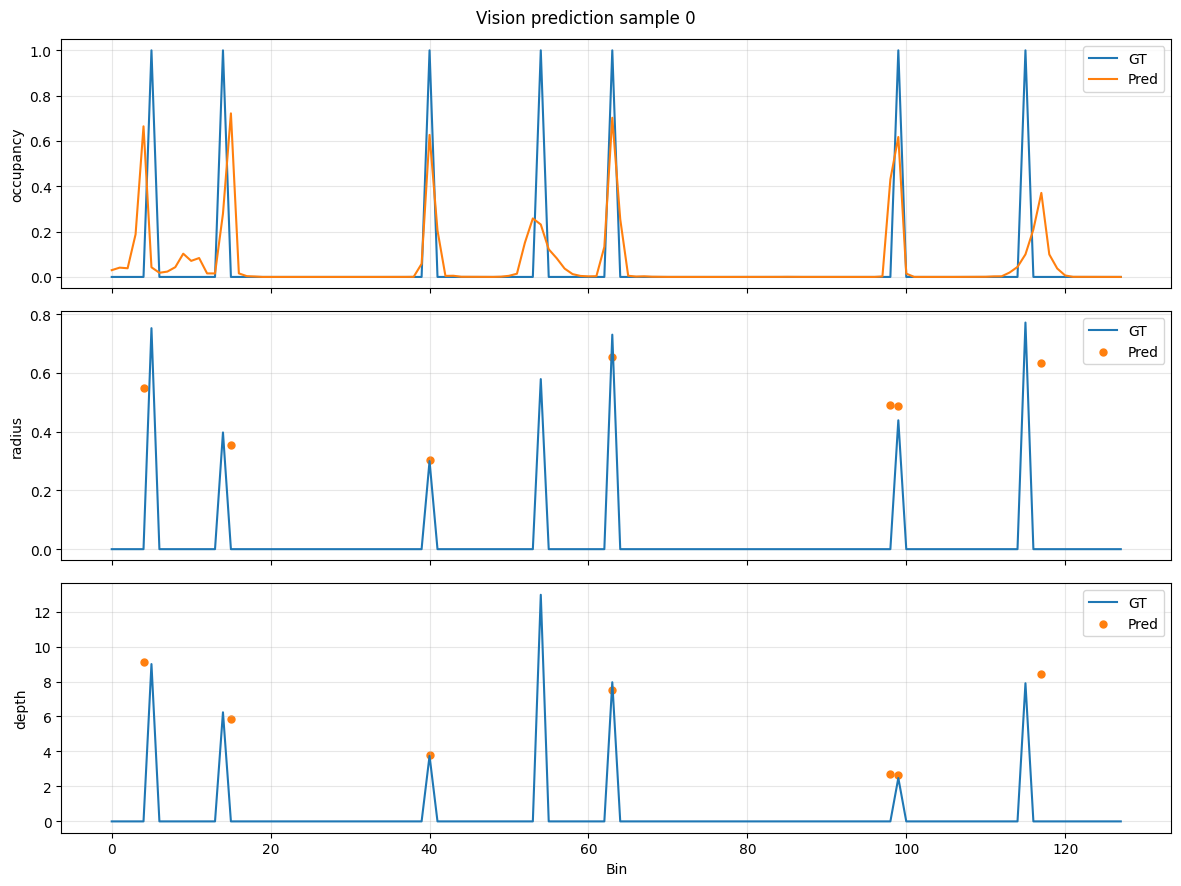

In [8]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(vision_a.shape[1])
PLOT_OCC_THRESHOLD = OCC_THRESHOLD
if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()
    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()
        ax.plot(bins, gt, label="GT", color="tab:blue")
        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter(bins[pr_mask], pr[pr_mask], label="Pred", color="tab:orange", s=25)
        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()


## 3. Estimated cylinders and input images


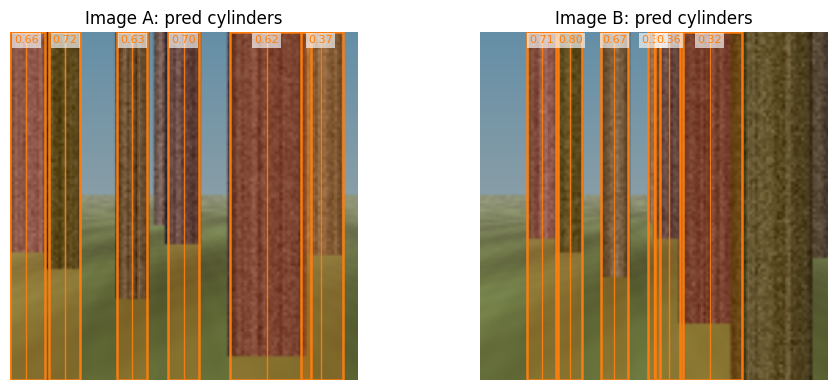

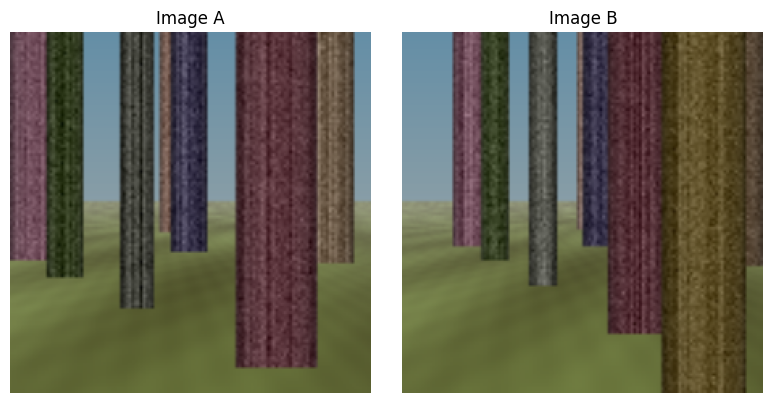

In [9]:
if INFERENCE_SHOW_IMAGES:
    fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
        [img_a[VISION_SAMPLE_IDX], img_b[VISION_SAMPLE_IDX]],
        [pred_vision[VISION_SAMPLE_IDX], pred_vision_b[VISION_SAMPLE_IDX]],
        titles=["Image A: pred cylinders", "Image B: pred cylinders"],
        occ_threshold=PLOT_OCC_THRESHOLD,
        flip_x=False,
    )
    plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


## 4. Relative pose


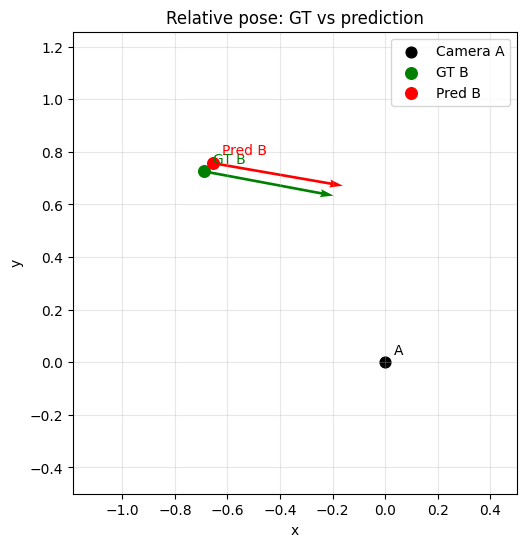

In [10]:
if not HAS_TRAINED_POSE:
    print("No trained pose head in this checkpoint; pose visualization is unavailable.")
elif pose_sample_valid:
    gt_pose = pose_ab[VISION_SAMPLE_IDX].detach().cpu()
    pred_pose_sample = pred_pose[VISION_SAMPLE_IDX].detach().cpu()
    if INFERENCE_SHOW_TEXT:
        print("GT :", pose_to_text(gt_pose))
        print("Pred:", pose_to_text(pred_pose_sample))
    if INFERENCE_SHOW_IMAGES:
        plot_relative_pose(gt_pose, pred_pose_sample)
else:
    print("Selected sample has no evaluable pose; select another VISION_SAMPLE_IDX.")


## 5. Training history (optional)

Plot epoch-aligned loss curves stored in the selected checkpoint.


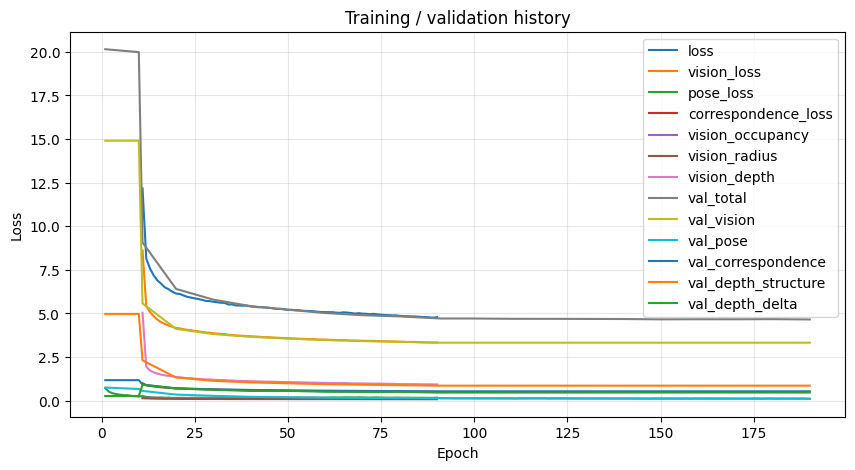

In [11]:
# Plot epoch-aligned loss curves when the selected checkpoint contains history.
if isinstance(history, dict):
    epochs = history.get("epoch", [])
    val_epochs = history.get("val_epoch", [])
    train_keys = ["loss", "vision_loss", "pose_loss", "correspondence_loss",
                  "vision_occupancy", "vision_radius", "vision_depth"]
    val_keys = ["val_total", "val_vision", "val_pose", "val_correspondence",
                "val_depth_structure", "val_depth_delta"]
    plt.figure(figsize=(10, 5))
    plotted = False
    for keys, xs in [(train_keys, epochs), (val_keys, val_epochs)]:
        for key in keys:
            ys = history.get(key, [])
            if len(xs) and len(ys) == len(xs):
                plt.plot(xs, ys, label=key)
                plotted = True
    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training / validation history")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    else:
        plt.close()
        print("History present, but no matching epoch-aligned loss curves.")
else:
    print("No training history stored in the selected checkpoint.")


In [12]:
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

from augmentations import build_eval_transform

FOREST_DIR = Path("forest_torpa")
OCC_THRESHOLD = 0.5  # En bin räknas som träff om occupancy-sannolikheten överstiger detta.
BATCH_SIZE = 16


class ForestImages(Dataset):
    def __init__(self, root, image_names, image_size):
        self.root = Path(root)
        self.image_names = image_names
        self.transform = build_eval_transform(image_size)

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        name = self.image_names[idx]
        with Image.open(self.root / "images" / name) as image:
            image = image.convert("RGB")
            return name, self.transform(image)


with open(FOREST_DIR / "relative_poses.json", encoding="utf-8") as f:
    pairs = json.load(f)

# Ta med varje bild en gång, även om den förekommer i flera par.
image_names = list(dict.fromkeys(
    name
    for pair in pairs
    for name in (pair["from_image"], pair["to_image"])
))

image_size = training_args.get("img_size", IMG_SIZE)
forest_loader = DataLoader(
    ForestImages(FOREST_DIR, image_names, image_size),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

all_probs = []
detections_per_image = []
image_results = []

model.eval()
with torch.inference_mode():
    for names, images in forest_loader:
        images = images.to(DEVICE)
        # Samma bild används i båda modellens vyer; vi redovisar vy A.
        pred, _, _ = model(
            images, images,
            compute_pose=False,
            return_corr=False,
        )
        probs = pred[..., 0].float().cpu().numpy()

        for name, p in zip(names, probs):
            detected = p > OCC_THRESHOLD
            all_probs.extend(p.tolist())
            detections_per_image.append(int(detected.sum()))
            image_results.append((name, p, int(detected.sum())))

all_probs = np.asarray(all_probs)
detected_images = sum(n > 0 for n in detections_per_image)

print(f"Bilder: {len(image_names)} | bildpar i metadata: {len(pairs)}")
print(f"Tröskel: {OCC_THRESHOLD:.2f}")
print(f"Bilder med minst en träff: {detected_images}/{len(image_names)} "
      f"({100 * detected_images / len(image_names):.1f}%)")
print(f"Träffar per bild: medel {np.mean(detections_per_image):.2f}, "
      f"median {np.median(detections_per_image):.0f}, "
      f"max {np.max(detections_per_image)}")
print(f"Alla bin: medel occupancy-sannolikhet {all_probs.mean():.3f}; "
      f"median {np.median(all_probs):.3f}")
print(f"Träffarnas sannolikhet: medel "
      f"{all_probs[all_probs > OCC_THRESHOLD].mean():.3f}"
      if np.any(all_probs > OCC_THRESHOLD) else "Inga bin över tröskeln.")

print("\nPer bild:")
for name, p, n in image_results:
    print(f"{name}: {n} träffar | högsta sannolikhet {p.max():.3f} "
          f"| medel occupancy {p.mean():.3f}")

Bilder: 229 | bildpar i metadata: 228
Tröskel: 0.50
Bilder med minst en träff: 135/229 (59.0%)
Träffar per bild: medel 0.98, median 1, max 5
Alla bin: medel occupancy-sannolikhet 0.117; median 0.093
Träffarnas sannolikhet: medel 0.600

Per bild:
000000.jpg: 1 träffar | högsta sannolikhet 0.537 | medel occupancy 0.144
000001.jpg: 0 träffar | högsta sannolikhet 0.452 | medel occupancy 0.151
000002.jpg: 0 träffar | högsta sannolikhet 0.449 | medel occupancy 0.138
000003.jpg: 1 träffar | högsta sannolikhet 0.515 | medel occupancy 0.123
000004.jpg: 2 träffar | högsta sannolikhet 0.606 | medel occupancy 0.132
000005.jpg: 1 träffar | högsta sannolikhet 0.602 | medel occupancy 0.131
000006.jpg: 0 träffar | högsta sannolikhet 0.440 | medel occupancy 0.143
000007.jpg: 1 träffar | högsta sannolikhet 0.664 | medel occupancy 0.150
000008.jpg: 4 träffar | högsta sannolikhet 0.721 | medel occupancy 0.148
000009.jpg: 4 träffar | högsta sannolikhet 0.585 | medel occupancy 0.132
000010.jpg: 0 träffar | 